# 03: Model A (1D CNN) vs classical methods on BIDMC

All numbers come from `data/bidmc.db`, built by `python -m breathcam.bidmc_eval`.

- 53 ICU patients, 4,809 windows of 30 s (5 s step); reference = mean of two annotators' breath-interval rates
- **Patient-level 5-fold cross-validation**: every CNN prediction is from a model that never saw that patient
- Methods: `welch`, `peaks` (Phase 1 code), `cnn1d` (learned from the raw respiration signal), `meanrate` (trivial baseline: mean rate of the training patients)
- No quality gate unless stated

In [1]:
import sys, json; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from breathcam import db
from breathcam.eval import load_windows, summarize, bootstrap_ci, mae, bland_altman

df = load_windows(db.connect("../data/bidmc.db"))
print(df.subject_id.nunique(), "patients;", df[df.method == "welch"].shape[0], "windows per method")

53 patients; 4809 windows per method


## 1. Headline: all windows, no gate

In [2]:
summarize(df, ["method"]).round(2).loc[["meanrate", "peaks", "welch", "cnn1d"]]

,n,mae,rmse,within_2,bias
method,,,,,
meanrate,4809,2.31,3.12,0.55,-0.01
peaks,4808,1.62,3.79,0.84,1.26
welch,4809,1.16,2.84,0.89,0.03
cnn1d,4809,0.98,1.80,0.88,0.05


95% confidence intervals for MAE, **resampling patients** (53 clusters):

In [3]:
for m in ["meanrate", "peaks", "welch", "cnn1d"]:
    p, lo, hi = bootstrap_ci(df[df.method == m], mae, "subject_id")
    print(f"{m:9s} MAE {p:.2f}   95% CI {lo:.2f} to {hi:.2f}")

meanrate  MAE 2.31   95% CI 1.82 to 2.85
peaks     MAE 1.62   95% CI 1.03 to 2.26


welch     MAE 1.16   95% CI 0.81 to 1.55
cnn1d     MAE 0.98   95% CI 0.69 to 1.38


### Is the CNN better than Welch? (paired, resampling patients)

The two intervals overlap, but both methods are scored on the same patients, so the paired difference is the right test.

In [4]:
wide = df.pivot_table(index=["subject_id", "window_start"], columns="method", values="est_bpm")
ref = df.drop_duplicates(["subject_id", "window_start"]).set_index(["subject_id", "window_start"]).ref_bpm
err = wide.sub(ref, axis=0).abs()
per = err.groupby(level=0).agg(["sum", "count"])
s_cnn, s_w, n = per[("cnn1d", "sum")].to_numpy(), per[("welch", "sum")].to_numpy(), per[("cnn1d", "count")].to_numpy()
rng = np.random.default_rng(0)
idx = rng.integers(0, len(n), (5000, len(n)))
diff = s_cnn[idx].sum(1) / n[idx].sum(1) - s_w[idx].sum(1) / n[idx].sum(1)
print(f"MAE(cnn1d) - MAE(welch) = {s_cnn.sum()/n.sum() - s_w.sum()/n.sum():+.2f}  95% CI {np.percentile(diff, 2.5):+.2f} to {np.percentile(diff, 97.5):+.2f}")
pm = pd.DataFrame({"cnn1d": s_cnn / n, "welch": s_w / n}, index=per.index)
print(f"CNN has lower MAE than Welch for {(pm.cnn1d < pm.welch).sum()} of {len(pm)} patients")

MAE(cnn1d) - MAE(welch) = -0.18  95% CI -0.57 to +0.18
CNN has lower MAE than Welch for 34 of 53 patients


## 2. Where does each method work? (by annotated rate)

In [5]:
d2 = df.assign(ref_range=pd.cut(df.ref_bpm, [0, 12, 20, 40], labels=["<12", "12-20", ">20"]))
summarize(d2, ["ref_range", "method"]).round(2)

n   mae  rmse  within_2  bias
ref_range method                                    
<12       cnn1d      191  5.24  6.40      0.30  5.24
          meanrate   191  8.39  8.80      0.00  8.39
          peaks      191  4.78  6.44      0.34  4.60
          welch      191  2.75  4.53      0.60  2.43
12-20     cnn1d     3803  0.70  1.03      0.93  0.04
          meanrate  3803  1.56  1.93      0.70  0.51
          peaks     3802  1.66  3.95      0.85  1.33
          welch     3803  1.17  2.89      0.89 -0.01
>20       cnn1d      815  1.30  2.11      0.77 -1.14
          meanrate   815  4.36  4.69      0.00 -4.36
          peaks      815  0.71  1.49      0.92  0.14
          welch      815  0.71  1.93      0.96 -0.33

## 3. With the quality gate (quality >= 0.6)

Caution: the gate is Welch's own quality score, so windows are chosen by how clean they look to Welch. This favours Welch and says nothing about the CNN's own confidence.

In [6]:
gated = df[df.quality_score >= 0.6]
print(f"{gated[gated.method == 'welch'].shape[0]} of {df[df.method == 'welch'].shape[0]} windows kept")
summarize(gated, ["method"]).round(2).loc[["meanrate", "peaks", "welch", "cnn1d"]]

3800 of 4809 windows kept


,n,mae,rmse,within_2,bias
method,,,,,
meanrate,3800,2.21,2.89,0.55,-0.27
peaks,3799,0.83,2.34,0.93,0.52
welch,3800,0.55,1.29,0.97,-0.02
cnn1d,3800,0.68,1.17,0.92,-0.01


## 4. Figures

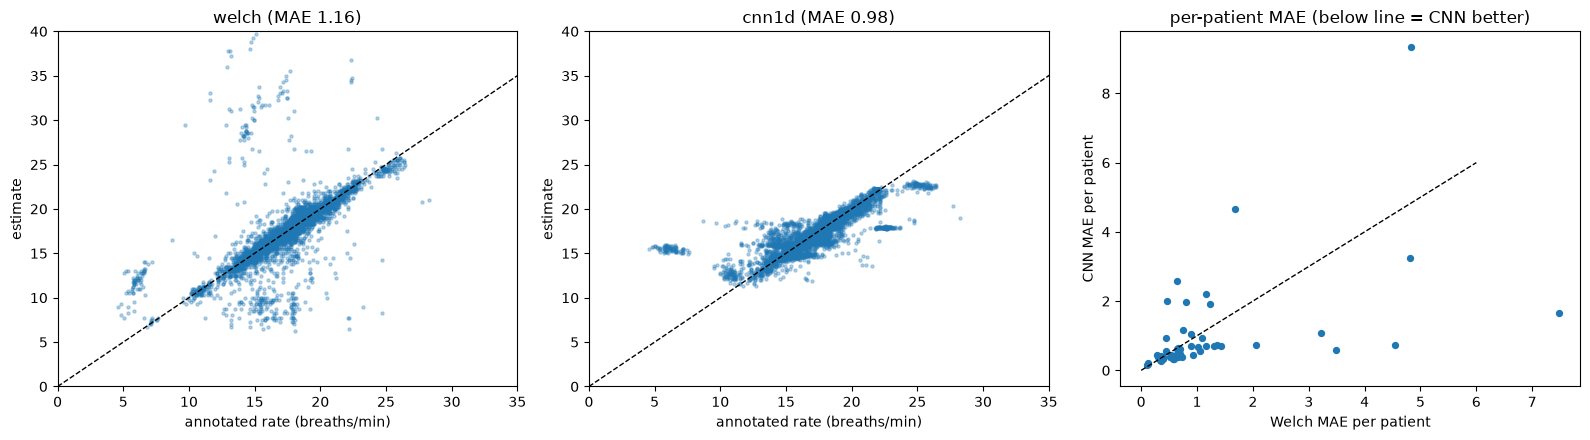

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, m in zip(ax[:2], ["welch", "cnn1d"]):
    d = df[df.method == m]
    a.scatter(d.ref_bpm, d.est_bpm, s=5, alpha=0.3); a.plot([0, 40], [0, 40], "k--", lw=1)
    a.set(xlim=(0, 35), ylim=(0, 40), xlabel="annotated rate (breaths/min)", ylabel="estimate", title=f"{m} (MAE {mae(d.est_bpm, d.ref_bpm):.2f})")
ax[2].scatter(pm.welch, pm.cnn1d, s=18); ax[2].plot([0, 6], [0, 6], "k--", lw=1)
ax[2].set(xlabel="Welch MAE per patient", ylabel="CNN MAE per patient", title="per-patient MAE (below line = CNN better)")
plt.tight_layout(); plt.savefig("../docs/figures/bidmc_cnn_vs_welch.png", dpi=150)

## 5. Training log (per fold)

In [8]:
pd.DataFrame(json.load(open("../data/bidmc_cv_log.json"))).round(2)

,fold,epochs,val_mae,test_mae
0,1,16,1.07,0.62
1,2,24,2.18,0.96
2,3,16,0.65,1.60
3,4,22,2.13,0.53
4,5,20,0.70,1.19


## Findings (BIDMC, 53 patients, patient-level 5-fold CV)

**Learning vs hand-tuned filtering.** The 1D CNN (MAE 0.98, 95% CI 0.69-1.38) is close to Welch (1.16, CI 0.81-1.55) and better than peak detection (1.62) and the trivial mean-rate baseline (2.31). The paired difference CNN minus Welch is -0.18 bpm with a 95% interval of -0.57 to +0.18 (resampling patients), so **on 53 patients the two are not statistically distinguishable**. The CNN has the lower MAE for 34 of 53 patients. It is clearly better on RMSE (1.80 vs 2.84) because it avoids Welch's gross errors, and about equal on within-2-bpm (88% vs 89%).

**Where each wins.** For the common range of 12-20 breaths/min (79% of windows) the CNN is better (MAE 0.70 vs 1.17). At the extremes it is worse: below 12 breaths/min (191 windows) MAE 5.24 vs 2.75, above 20 (815 windows) 1.30 vs 0.71. The scatter plot shows why: the CNN squeezes its predictions towards the middle (a patient breathing about 6 breaths/min is predicted near 15), the classic regression-to-the-mean behaviour of a regressor trained on data concentrated at 12-20. Welch has the opposite weakness: occasional large errors where noise or a harmonic beats the true peak.

**Quality gate.** With Welch's own quality score >= 0.6 (3,800 of 4,809 windows), Welch scores 0.55 and the CNN 0.68. This comparison favours Welch because the gate is Welch's confidence; it does not measure the CNN's own reliability. The CNN has no confidence output yet.

**Caveats.** One architecture, one seed, no hyperparameter search; fold test MAE ranges from 0.53 to 1.60, and a few patients dominate the error (one patient has CNN MAE of about 9). The reference is manual annotation of the same impedance signal the methods read. This is adult ICU data, and it says nothing about video or children. A fair test of whether learning helps on video needs a video dataset with several subjects.